# EDA các trang crawl lỗi

Notebook này phân tích các trang không crawl được và drill-down các domain có **0 trang crawl thành công**.

- `dataset.jsonl`: các record crawl thành công.
- `crawl_attempts.jsonl`: toàn bộ lượt thử, gồm cả thành công và lỗi; đây là nguồn của log lỗi.

> Trong dữ liệu gốc, `domain` là chuỗi tên miền chứ không phải số. Cụm “domain bằng 0” được hiểu là `success_count == 0` sau khi tổng hợp theo domain.

In [ ]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_rows", 200)

def find_data_dir():
    candidates = [Path.cwd(), Path.cwd() / "domain_cleanliness"]
    try:
        candidates.append(Path(__file__).resolve().parent)
    except NameError:
        pass
    for path in candidates:
        if (path / "dataset.jsonl").exists():
            return path
    raise FileNotFoundError("Không tìm thấy dataset.jsonl. Hãy chạy notebook từ thư mục domain_cleanliness hoặc đặt DATA_DIR thủ công.")

DATA_DIR = find_data_dir()
DATASET_PATH = DATA_DIR / "dataset.jsonl"
ATTEMPTS_PATH = DATA_DIR / "crawl_attempts.jsonl"
DATA_DIR


PosixPath('/Volumes/security/lucraft@lucraftmeds/lucraftmeds@notebooks/data-creation/domain-samples-key-noise-extraction/domain_cleanliness')

In [2]:
def read_jsonl(path):
    rows = []
    bad_lines = []
    with path.open(encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            if not line.strip():
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as exc:
                bad_lines.append({"line_no": line_no, "error": str(exc)})
    return pd.DataFrame(rows), pd.DataFrame(bad_lines)

dataset, dataset_bad_lines = read_jsonl(DATASET_PATH)
if ATTEMPTS_PATH.exists():
    attempts, attempts_bad_lines = read_jsonl(ATTEMPTS_PATH)
else:
    attempts, attempts_bad_lines = dataset.copy(), pd.DataFrame()
    print("CẢNH BÁO: Không có crawl_attempts.jsonl; dataset.jsonl có thể không chứa các lượt crawl lỗi.")

print(f"dataset.jsonl: {len(dataset):,} rows")
print(f"crawl_attempts.jsonl: {len(attempts):,} rows")
print(f"Dòng JSON lỗi: {len(dataset_bad_lines) + len(attempts_bad_lines):,}")


dataset.jsonl: 791 rows
crawl_attempts.jsonl: 1,462 rows
Dòng JSON lỗi: 0


## 1. Tổng quan crawl

In [3]:
attempts["success"] = attempts["success"].fillna(False).astype(bool)
failed = attempts.loc[~attempts["success"]].copy()
domain_col = "sampled_domain" if "sampled_domain" in attempts.columns else "domain"

overview = pd.Series({
    "total_attempts": len(attempts),
    "successful_attempts": int(attempts["success"].sum()),
    "failed_attempts": len(failed),
    "success_rate_pct": round(attempts["success"].mean() * 100, 2),
    "domains": attempts[domain_col].nunique(dropna=True),
    "domains_with_failures": failed[domain_col].nunique(dropna=True),
}, name="value").to_frame()
display(overview)
display(attempts["success"].value_counts(dropna=False).rename_axis("success").to_frame("count"))


,value
total_attempts,1462.0
successful_attempts,791.0
failed_attempts,671.0
success_rate_pct,54.1
domains,97.0
domains_with_failures,39.0


,count
success,
True,791
False,671


## 2. Chuẩn hoá và thống kê loại lỗi

,count,domains,pct_of_failures
error_category,,,
timeout,366,19,54.55
anti_bot,253,14,37.70
batch_error,49,9,7.30
crawl_error,2,1,0.30
empty_content,1,1,0.15


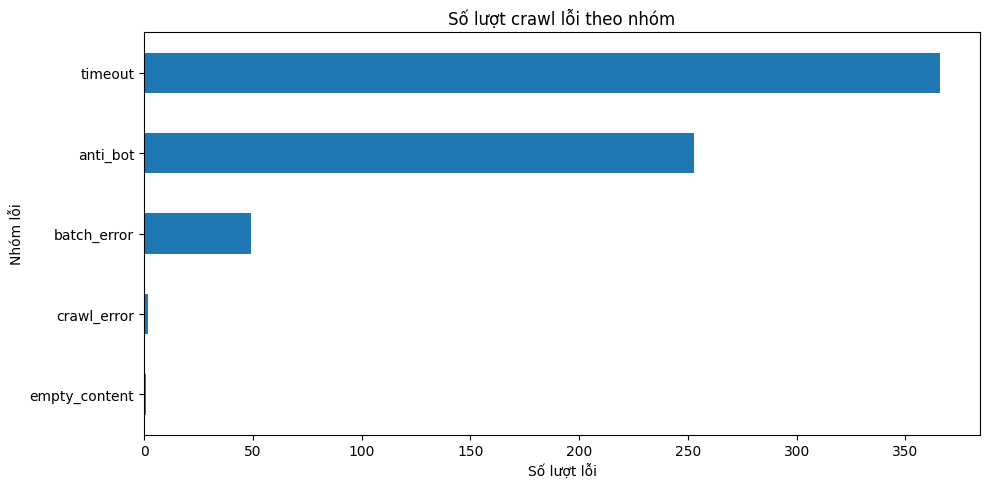

In [4]:
def classify_error(row):
    text = f"{row.get('error_type') or ''} {row.get('error') or ''}".lower()
    status = row.get("final_status_code") or row.get("status_code")
    if "anti-bot" in text or "captcha" in text or "cloudflare" in text:
        return "anti_bot"
    if status in (401, 403) or re.search(r"\b(401|403)\b", text):
        return "access_denied"
    if status == 404 or re.search(r"\b404\b", text):
        return "not_found"
    if status == 429 or re.search(r"\b429\b|rate.?limit|too many requests", text):
        return "rate_limited"
    if (isinstance(status, (int, float)) and 500 <= status < 600) or re.search(r"\b5\d\d\b", text):
        return "server_error_5xx"
    if re.search(r"timeout|timed out", text):
        return "timeout"
    if re.search(r"dns|name or service not known|resolve host|nodename nor servname", text):
        return "dns_error"
    if re.search(r"ssl|certificate|tls", text):
        return "ssl_tls_error"
    if re.search(r"connection|connect error|network", text):
        return "connection_error"
    if re.search(r"empty|no content|markdown.*0|content.*0", text):
        return "empty_content"
    return row.get("error_type") or "unknown"

failed["error_category"] = failed.apply(classify_error, axis=1)
error_summary = (failed.groupby("error_category", dropna=False)
                 .agg(count=("url", "size"), domains=(domain_col, "nunique"))
                 .sort_values("count", ascending=False))
error_summary["pct_of_failures"] = (error_summary["count"] / len(failed) * 100).round(2)
display(error_summary)

ax = error_summary.sort_values("count")["count"].plot.barh(figsize=(10, 5), title="Số lượt crawl lỗi theo nhóm")
ax.set_xlabel("Số lượt lỗi")
ax.set_ylabel("Nhóm lỗi")
plt.tight_layout()
plt.show()


In [5]:
# Các thông báo lỗi gốc phổ biến nhất (không làm mất chi tiết log)
raw_error_summary = (failed.assign(error_message=failed["error"].fillna("<missing>"))
                     .groupby(["error_type", "error_message"], dropna=False)
                     .size().rename("count").reset_index()
                     .sort_values("count", ascending=False))
display(raw_error_summary.head(50))


,error_type,error_message,count
5,crawl_error,Blocked by anti-bot protection: HTTP 403 with HTML content (1025 bytes),106
8,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",60
0,batch_error,MemoryError: Memory usage exceeded threshold for 600.0 seconds,49
6,crawl_error,Blocked by anti-bot protection: HTTP 403 with HTML content (144 bytes),30
4,crawl_error,Blocked by anti-bot protection: Cloudflare JS challenge,23
7,crawl_error,Blocked by anti-bot protection: HTTP 403 with HTML content (4689 bytes),12
12,crawl_error,Blocked by anti-bot protection: Structural: no <body> tag (452 bytes),11
11,crawl_error,Blocked by anti-bot protection: Structural: no <body> tag (118 bytes),5
10,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements, script_heavy_shell (10299 bytes, 22 chars visible)",3
259,crawl_error,Unexpected error in _crawl_web at line 778 in _crawl_web (../../../../../../opt/homebrew/lib/python3.10/site-packages/crawl4ai/async_crawler_strategy.py):\nError: Failed on nav...,1


## 3. Thống kê theo domain và tìm domain có 0 thành công

In [6]:
domain_summary = (attempts.groupby(domain_col, dropna=False)
                  .agg(total_attempts=("url", "size"),
                       success_count=("success", "sum"))
                  .reset_index())
domain_summary["success_count"] = domain_summary["success_count"].astype(int)
domain_summary["failure_count"] = domain_summary["total_attempts"] - domain_summary["success_count"]
domain_summary["success_rate_pct"] = (domain_summary["success_count"] / domain_summary["total_attempts"] * 100).round(2)
domain_summary = domain_summary.sort_values(["success_count", "failure_count"], ascending=[True, False])

zero_success_domains = domain_summary.loc[domain_summary["success_count"].eq(0)].copy()
print(f"Có {len(zero_success_domains):,} domain có 0 trang crawl thành công.")
display(zero_success_domains)


Có 11 domain có 0 trang crawl thành công.


,sampled_domain,total_attempts,success_count,failure_count,success_rate_pct
2,article.iiyi.com,30,0,30,0.0
7,baidianfeng.familydoctor.com.cn,30,0,30,0.0
25,bingli.iiyi.com,30,0,30,0.0
33,familydoctor.com.cn,30,0,30,0.0
61,pmc-ecm-healthblog.beta.pharmacity.io,30,0,30,0.0
64,qy.familydoctor.com.cn,30,0,30,0.0
80,v.familydoctor.com.cn,10,0,10,0.0
4,ask.familydoctor.com.cn,3,0,3,0.0
90,yanglao.familydoctor.com.cn,2,0,2,0.0
68,special.vietnamplus.vn,1,0,1,0.0


## 4. Log lỗi của các domain có 0 thành công

In [7]:
zero_domain_logs = failed.loc[failed[domain_col].isin(zero_success_domains[domain_col])].copy()
log_columns = [c for c in [domain_col, "domain_id", "url", "final_url", "status_code",
                                  "final_status_code", "error_category", "error_type", "error", "crawled_at"]
               if c in zero_domain_logs.columns]
zero_domain_logs = zero_domain_logs[log_columns].sort_values([domain_col, "error_category", "url"])
display(zero_domain_logs)


,sampled_domain,domain_id,url,final_url,status_code,final_status_code,error_category,error_type,error,crawled_at
793,article.iiyi.com,d048,https://article.iiyi.com/detail/18640.html,https://article.iiyi.com/detail/18640.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:15.547603+00:00
792,article.iiyi.com,d048,https://article.iiyi.com/detail/18983.html,https://article.iiyi.com/detail/18983.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:15.547570+00:00
812,article.iiyi.com,d048,https://article.iiyi.com/detail/193827.html,https://article.iiyi.com/detail/193827.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:30.798867+00:00
802,article.iiyi.com,d048,https://article.iiyi.com/detail/196255.html,https://article.iiyi.com/detail/196255.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:25.664174+00:00
803,article.iiyi.com,d048,https://article.iiyi.com/detail/200109.html,https://article.iiyi.com/detail/200109.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:25.664203+00:00
814,article.iiyi.com,d048,https://article.iiyi.com/detail/201077.html,https://article.iiyi.com/detail/201077.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:30.798903+00:00
794,article.iiyi.com,d048,https://article.iiyi.com/detail/20571.html,https://article.iiyi.com/detail/20571.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:15.547612+00:00
813,article.iiyi.com,d048,https://article.iiyi.com/detail/22098.html,https://article.iiyi.com/detail/22098.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:30.798894+00:00
815,article.iiyi.com,d048,https://article.iiyi.com/detail/23426.html,https://article.iiyi.com/detail/23426.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:30.798910+00:00
795,article.iiyi.com,d048,https://article.iiyi.com/detail/25626.html,https://article.iiyi.com/detail/25626.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:15.547618+00:00


In [8]:
# Ma trận domain × loại lỗi: nhìn nhanh nguyên nhân khiến từng domain về 0
zero_domain_error_matrix = pd.crosstab(zero_domain_logs[domain_col], zero_domain_logs["error_category"])
zero_domain_error_matrix["total_errors"] = zero_domain_error_matrix.sum(axis=1)
zero_domain_error_matrix = zero_domain_error_matrix.sort_values("total_errors", ascending=False)
display(zero_domain_error_matrix)


error_category,anti_bot,total_errors
sampled_domain,,
article.iiyi.com,30,30
baidianfeng.familydoctor.com.cn,30,30
bingli.iiyi.com,30,30
familydoctor.com.cn,30,30
pmc-ecm-healthblog.beta.pharmacity.io,30,30
qy.familydoctor.com.cn,30,30
v.familydoctor.com.cn,10,10
ask.familydoctor.com.cn,3,3
yanglao.familydoctor.com.cn,2,2


## 5. Tra cứu nhanh một domain

In [9]:
# Đổi giá trị này để xem toàn bộ log của một domain cụ thể.
SELECTED_DOMAIN = zero_success_domains[domain_col].iloc[0] if len(zero_success_domains) else None
print("SELECTED_DOMAIN =", SELECTED_DOMAIN)
if SELECTED_DOMAIN is not None:
    display(zero_domain_logs.loc[zero_domain_logs[domain_col].eq(SELECTED_DOMAIN)])


SELECTED_DOMAIN = article.iiyi.com


,sampled_domain,domain_id,url,final_url,status_code,final_status_code,error_category,error_type,error,crawled_at
793,article.iiyi.com,d048,https://article.iiyi.com/detail/18640.html,https://article.iiyi.com/detail/18640.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:15.547603+00:00
792,article.iiyi.com,d048,https://article.iiyi.com/detail/18983.html,https://article.iiyi.com/detail/18983.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:15.547570+00:00
812,article.iiyi.com,d048,https://article.iiyi.com/detail/193827.html,https://article.iiyi.com/detail/193827.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:30.798867+00:00
802,article.iiyi.com,d048,https://article.iiyi.com/detail/196255.html,https://article.iiyi.com/detail/196255.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:25.664174+00:00
803,article.iiyi.com,d048,https://article.iiyi.com/detail/200109.html,https://article.iiyi.com/detail/200109.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:25.664203+00:00
814,article.iiyi.com,d048,https://article.iiyi.com/detail/201077.html,https://article.iiyi.com/detail/201077.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:30.798903+00:00
794,article.iiyi.com,d048,https://article.iiyi.com/detail/20571.html,https://article.iiyi.com/detail/20571.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:15.547612+00:00
813,article.iiyi.com,d048,https://article.iiyi.com/detail/22098.html,https://article.iiyi.com/detail/22098.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:30.798894+00:00
815,article.iiyi.com,d048,https://article.iiyi.com/detail/23426.html,https://article.iiyi.com/detail/23426.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:30.798910+00:00
795,article.iiyi.com,d048,https://article.iiyi.com/detail/25626.html,https://article.iiyi.com/detail/25626.html,521.0,521.0,anti_bot,crawl_error,"Blocked by anti-bot protection: Structural: minimal_text, no_content_elements (39 bytes, 0 chars visible)",2026-10-10T15:12:15.547618+00:00


## 6. Xuất kết quả (tuỳ chọn)

In [10]:
# Bỏ comment nếu muốn lưu kết quả để xử lý tiếp.
error_summary.to_csv(DATA_DIR / "error_summary.csv", encoding="utf-8-sig")
zero_success_domains.to_csv(DATA_DIR / "zero_success_domains.csv", index=False, encoding="utf-8-sig")
zero_domain_logs.to_csv(DATA_DIR / "zero_success_domain_logs.csv", index=False, encoding="utf-8-sig")
